In [2]:

# CodeAlpha Data Analytics Internship
# Task 3: Data Visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from pathlib import Path

# Set a consistent visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("CodeAlpha - Task 3: Data Visualization")
print("Libraries imported successfully.")


CodeAlpha - Task 3: Data Visualization
Libraries imported successfully.


In [4]:

# Upload the Online Retail Excel dataset
uploaded = files.upload()

# Find the uploaded Excel file
excel_files = [
    name for name in uploaded
    if name.lower().endswith(".xlsx")
]

if not excel_files:
    raise ValueError("Please upload the Online Retail Excel (.xlsx) dataset.")

# Load the dataset
df = pd.read_excel(excel_files[0])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Saving Online Retail.xlsx to Online Retail (1).xlsx
Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:

# Create a copy so the original dataset remains unchanged
viz_df = df.copy()

# Remove duplicate records
viz_df = viz_df.drop_duplicates().copy()

# Remove rows missing essential analysis fields
viz_df = viz_df.dropna(
    subset=["InvoiceNo", "Description", "InvoiceDate",
            "Quantity", "UnitPrice", "Country"]
).copy()

# Exclude cancelled invoices and invalid transactions
viz_df = viz_df[
    ~viz_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

viz_df = viz_df[
    (viz_df["Quantity"] > 0) &
    (viz_df["UnitPrice"] > 0)
].copy()

# Convert invoice dates and calculate revenue
viz_df["InvoiceDate"] = pd.to_datetime(viz_df["InvoiceDate"])
viz_df["Revenue"] = viz_df["Quantity"] * viz_df["UnitPrice"]

print("Data preparation completed!")
print("Original rows:", len(df))
print("Rows after cleaning:", len(viz_df))
print(f"Total revenue: £{viz_df['Revenue'].sum():,.2f}")

display(viz_df.head())


Data preparation completed!
Original rows: 541909
Rows after cleaning: 524878
Total revenue: £10,642,110.80


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


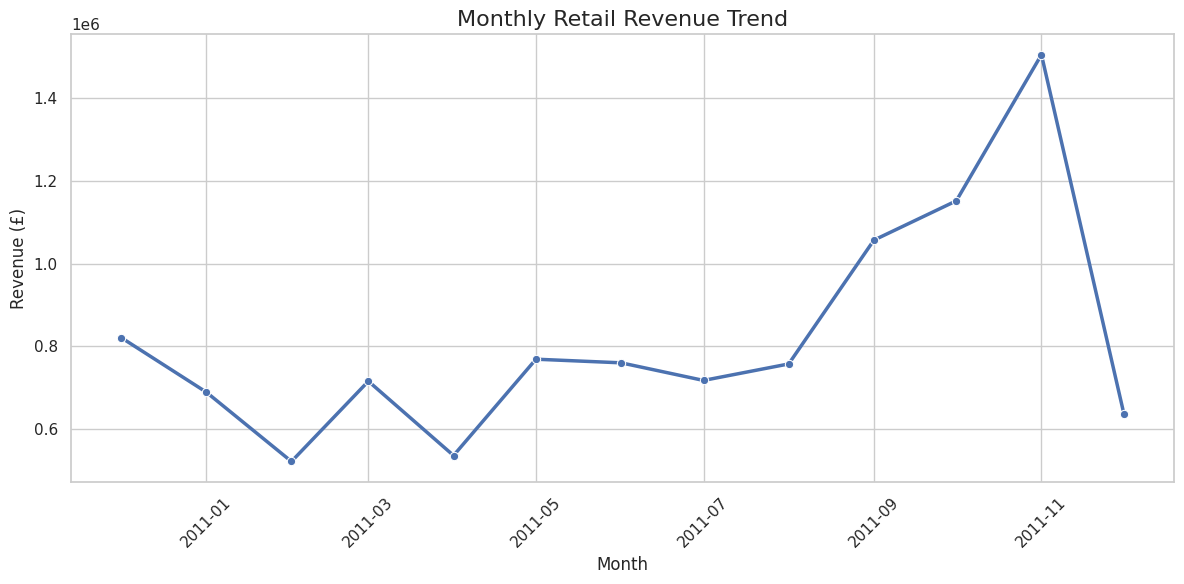

,Month,Revenue
0,2010-12-01,821452.730
1,2011-01-01,689811.610
2,2011-02-01,522545.560
3,2011-03-01,716215.260
4,2011-04-01,536968.491
5,2011-05-01,769296.610
6,2011-06-01,760547.010
7,2011-07-01,718076.121
8,2011-08-01,757841.380
9,2011-09-01,1056435.192


In [6]:

# Visualization 1: Monthly Revenue Trend

viz_df["Month"] = viz_df["InvoiceDate"].dt.to_period("M")

monthly_revenue = (
    viz_df.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

# Convert month periods to timestamps for plotting
monthly_revenue["Month"] = monthly_revenue["Month"].dt.to_timestamp()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Revenue",
    marker="o",
    linewidth=2.5
)

plt.title("Monthly Retail Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_revenue)


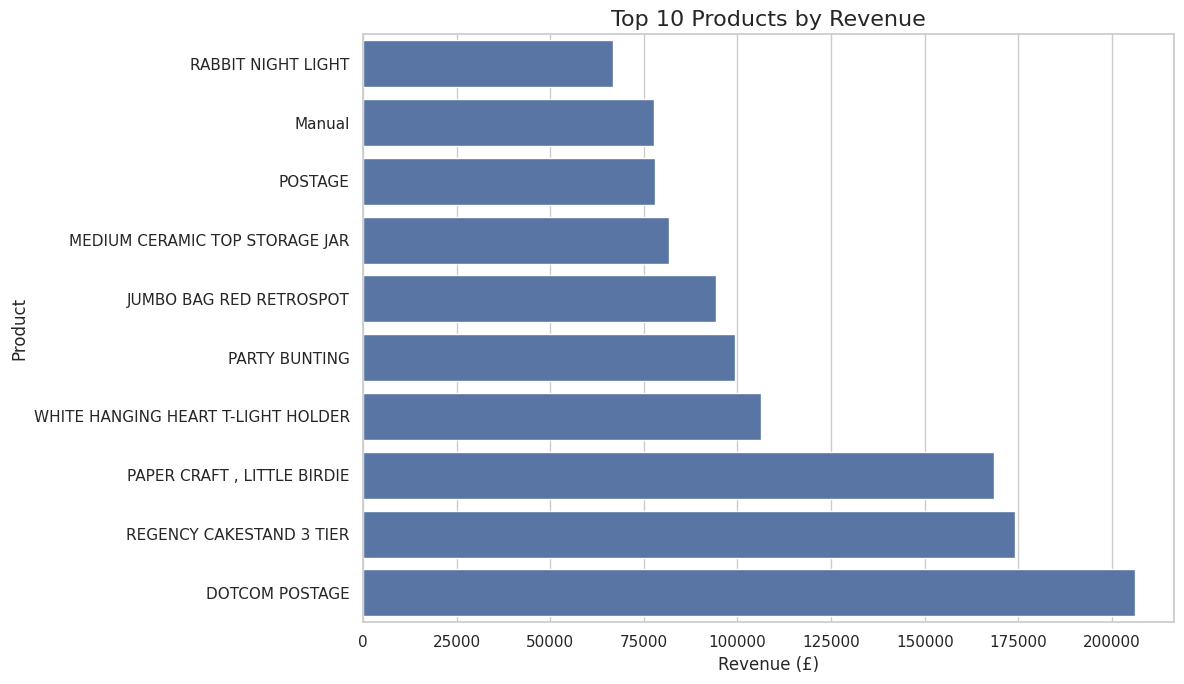

,Description,Revenue
9,DOTCOM POSTAGE,206248.77
8,REGENCY CAKESTAND 3 TIER,174156.54
7,"PAPER CRAFT , LITTLE BIRDIE",168469.60
6,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
5,PARTY BUNTING,99445.23
4,JUMBO BAG RED RETROSPOT,94159.81
3,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
2,POSTAGE,78101.88
1,Manual,77752.82
0,RABBIT NIGHT LIGHT,66870.03


In [8]:

# Visualization 2: Top 10 Products by Revenue

product_revenue = (
    viz_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=product_revenue,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()

# Save the chart for the GitHub project
Path("outputs").mkdir(exist_ok=True)
plt.savefig("outputs/top_10_products.png", dpi=300, bbox_inches="tight")

plt.show()

display(product_revenue.sort_values("Revenue", ascending=False))


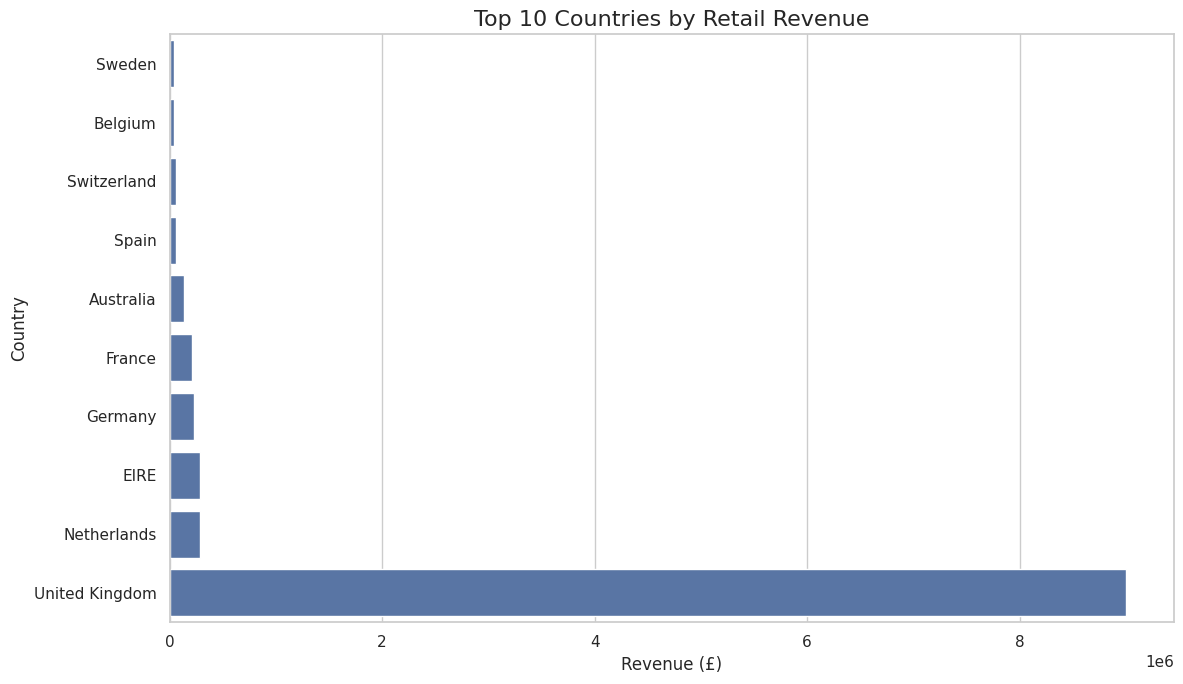

,Country,Revenue
9,United Kingdom,9001744.094
8,Netherlands,285446.340
7,EIRE,283140.520
6,Germany,228678.400
5,France,209625.370
4,Australia,138453.810
3,Spain,61558.560
2,Switzerland,57067.600
1,Belgium,41196.340
0,Sweden,38367.830


In [9]:

# Visualization 3: Top 10 Countries by Revenue

country_revenue = (
    viz_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=country_revenue,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Retail Revenue", fontsize=16)
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()

# Save the chart
plt.savefig(
    "outputs/top_10_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(country_revenue.sort_values("Revenue", ascending=False))


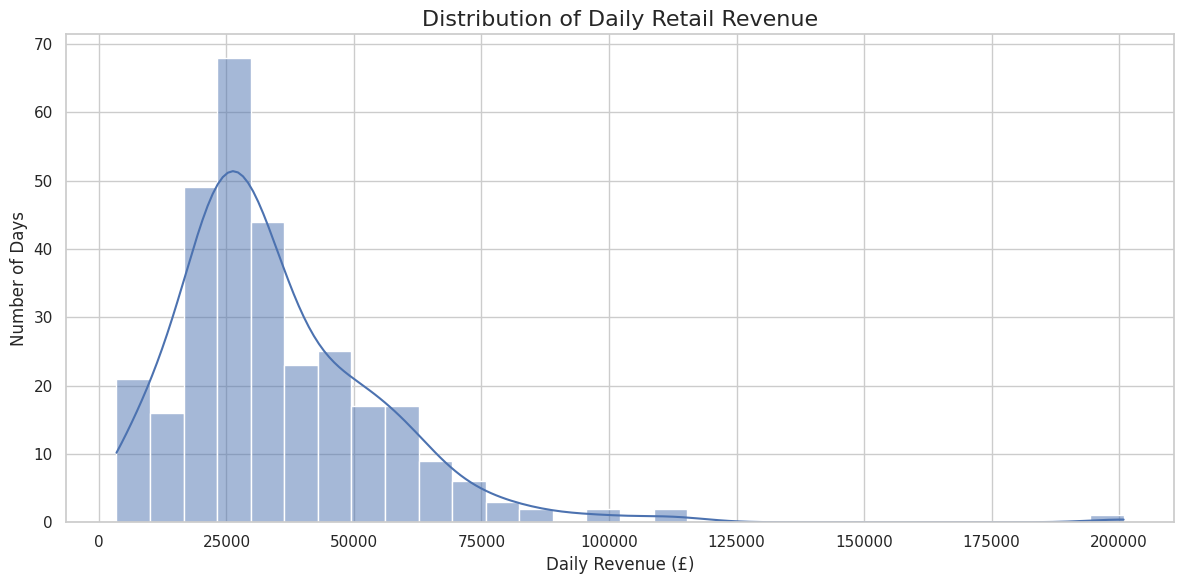

Daily revenue summary:


,DailyRevenue
count,305.000000
mean,34892.166570
std,21098.282521
min,3439.670000
25%,22345.930000
50%,29526.290000
75%,45277.920000
max,200900.980000


In [10]:

# Visualization 4: Daily Revenue Distribution

daily_revenue = (
    viz_df.groupby(viz_df["InvoiceDate"].dt.date)["Revenue"]
    .sum()
    .reset_index(name="DailyRevenue")
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=daily_revenue,
    x="DailyRevenue",
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Retail Revenue", fontsize=16)
plt.xlabel("Daily Revenue (£)")
plt.ylabel("Number of Days")
plt.tight_layout()

# Save the chart
plt.savefig(
    "outputs/daily_revenue_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Daily revenue summary:")
display(daily_revenue["DailyRevenue"].describe().to_frame())


In [11]:

# Save datasets and visualization outputs

Path("outputs").mkdir(exist_ok=True)

monthly_revenue.to_csv(
    "outputs/monthly_revenue.csv", index=False
)

product_revenue.to_csv(
    "outputs/top_10_products.csv", index=False
)

country_revenue.to_csv(
    "outputs/top_10_countries.csv", index=False
)

daily_revenue.to_csv(
    "outputs/daily_revenue.csv", index=False
)

print("All visualization datasets saved successfully!")
print("\nSaved chart files:")

for file in sorted(Path("outputs").glob("*.png")):
    print(file)


All visualization datasets saved successfully!

Saved chart files:
outputs/daily_revenue_distribution.png
outputs/top_10_countries.png
outputs/top_10_products.png


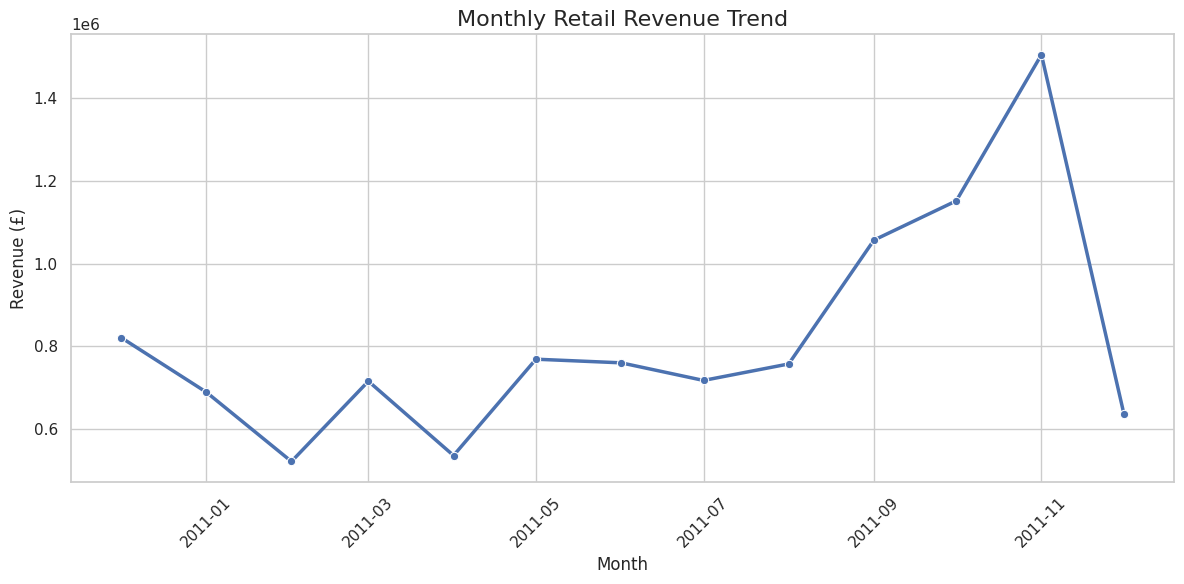

Files in outputs folder:
daily_revenue.csv
daily_revenue_distribution.png
monthly_revenue.csv
monthly_revenue.png
top_10_countries.csv
top_10_countries.png
top_10_products.csv
top_10_products.png


In [12]:

# Save the monthly chart
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Revenue",
    marker="o",
    linewidth=2.5
)
plt.title("Monthly Retail Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "outputs/monthly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Verify all saved files
print("Files in outputs folder:")
for file in sorted(Path("outputs").glob("*")):
    print(file.name)
